# SEM illumination · an RTM image under a hill, compensated

A reverse-time-migration image is the FWI gradient with the reflected data as the adjoint
source. Its amplitudes follow how much energy reached each point: bright near the surface, dim
at depth and under the flanks of a hill. Dividing by the illumination balances them.
`PropSEM.compute_illumination` returns PropTorch's pair, in the model's shape like the gradient:

| | | |
|---|---|---|
| `source_illumination` | `sum_t |a|^2`, `a` the source wavefield's second time derivative | the pseudo-Hessian |
| `receiver_illumination` | `sum_t |lambda|^2`, `lambda` the adjoint wavefield | after `backward()` |

See [Illumination](../../user-guide/sem/#illumination) in the user guide.

In [1]:
import numpy as np
import torch
import matplotlib.pyplot as plt
from scipy.ndimage import gaussian_filter

from sweep.sem import AcousticPotentialSEM2D, PropSEM

DEV = "cuda" if torch.cuda.is_available() else "cpu"
DH, NO = 5.0, 4                          # grid cell; elements of 4 cells = 20 m
NX, NZ = 401, 201                        # 2000 m x 1000 m
F0, T_REC = 12.0, 1.2
DT = 2.5e-4
NT = int(round(T_REC / DT))
xg = np.arange(NX) * DH
zg = np.arange(NZ) * DH


def surface(x):
    """Surface depth (m): 150 m, a hill rising to 40 m at x = 1000 m."""
    return 150.0 - 110.0 * np.exp(-((x - 1000.0) / 250.0) ** 2)

## 1. Model and acquisition

A velocity gradient below the surface, a flat reflector at 500 m and a dipping one from 650 to
800 m. The migration model is the true one smoothed (the cells above the surface take the
surface velocity first, so the smoothing does not reach into the air). Twelve shots 10 m
below the surface, receivers every 10 m 5 m below it.

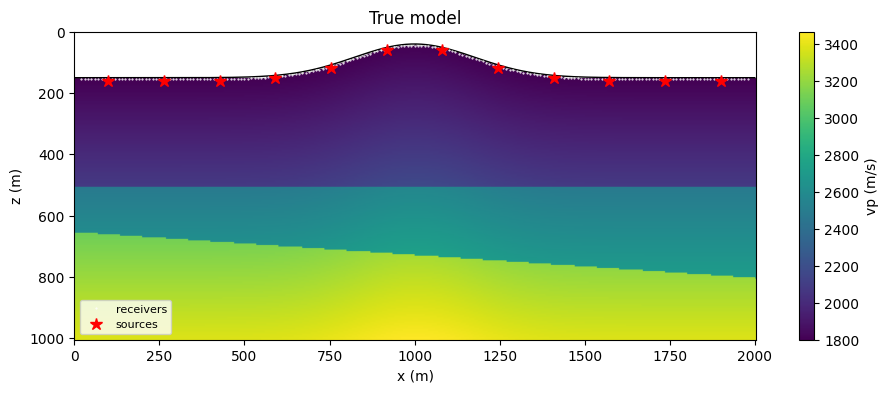

In [2]:
top = surface(xg)
Z, X = np.meshgrid(zg, xg, indexing="ij")
depth = np.clip(Z - top[None, :], 0.0, None)
vp_true = 1800.0 + 0.8 * depth
vp_true += np.where(Z > 500.0, 400.0, 0.0)
vp_true += np.where(Z > 650.0 + 150.0 * X / 2000.0, 500.0, 0.0)
vp_true = vp_true.astype(np.float32)
vp_smooth = gaussian_filter(np.where(Z < top[None, :], 1800.0, vp_true), sigma=8).astype(np.float32)

x_src = np.linspace(100.0, 1900.0, 12)
x_rec = np.arange(20.0, 1981.0, 10.0)
src = np.stack([x_src / DH, (surface(x_src) + 10.0) / DH], 1)
rec_one = np.stack([x_rec / DH, (surface(x_rec) + 5.0) / DH], 1)
rec = np.repeat(rec_one[None], len(x_src), 0)

fig, ax = plt.subplots(figsize=(11, 4))
im = ax.imshow(np.where(Z < top[None, :], np.nan, vp_true), cmap="viridis", aspect="auto",
               extent=[0, NX * DH, NZ * DH, 0])
ax.plot(xg, top, "k", lw=1)
ax.plot(x_rec, surface(x_rec) + 5.0, "w.", ms=1, label="receivers")
ax.plot(x_src, surface(x_src) + 10.0, "r*", ms=9, label="sources")
ax.set_xlabel("x (m)"); ax.set_ylabel("z (m)"); ax.legend(loc="lower left", fontsize=8)
ax.set_title("True model"); fig.colorbar(im, ax=ax, label="vp (m/s)"); plt.show()

## 2. Data and residual

`topography` gives the surface row per column, and the mesh follows it. The receivers record
the potential `chi`, the equation's field. The observed data come from the true model; the
data of the smooth model hold the direct and diving waves, so the residual is the reflected
energy, the adjoint source of the migration.

impl c, data (12, 4800, 197, 1)


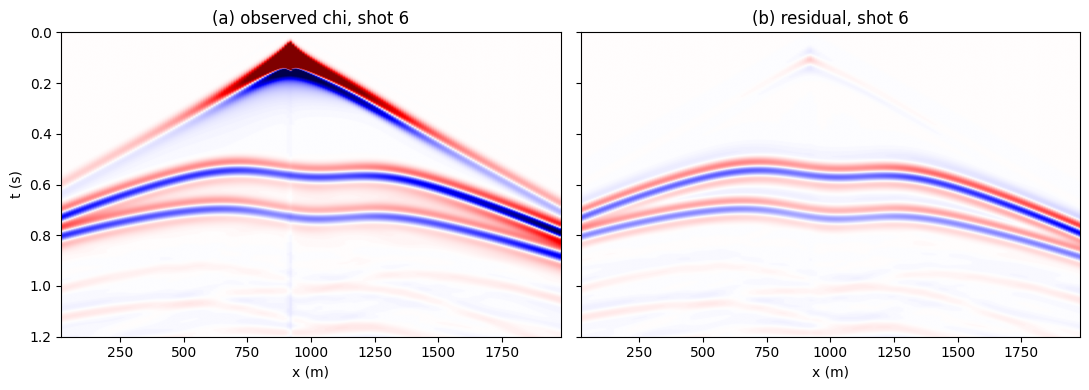

In [3]:
solver = PropSEM(AcousticPotentialSEM2D, shape=(NZ, NX), dh=DH, dt=DT, n_order=NO,
                 topography=top / DH, f_dominant=F0, dev=DEV,
                 source_type=["chi"], receiver_type=["chi"])
t = np.arange(NT) * DT
a = (np.pi * F0 * (t - 1.2 / F0)) ** 2
wav = torch.tensor((1.0 - 2.0 * a) * np.exp(-a), dtype=torch.float32, device=DEV)
vt = torch.tensor(vp_true, device=DEV)
vs = torch.tensor(vp_smooth, device=DEV)
with torch.no_grad():
    obs = solver(wav, src, rec, models=[vt])
    res = obs - solver(wav, src, rec, models=[vs])
print(f"impl {solver.impl}, data {tuple(obs.shape)}")

v = np.quantile(np.abs(obs[5, :, :, 0].cpu().numpy()), 0.99)
fig, ax = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for k, (d, title) in enumerate(((obs, "(a) observed chi, shot 6"), (res, "(b) residual, shot 6"))):
    ax[k].imshow(d[5, :, :, 0].cpu().numpy(), cmap="seismic", vmin=-v, vmax=v, aspect="auto",
                 extent=[x_rec[0], x_rec[-1], T_REC, 0])
    ax[k].set_title(title); ax[k].set_xlabel("x (m)")
ax[0].set_ylabel("t (s)"); plt.tight_layout(); plt.show()

## 3. Migration with the illumination

As in notebook 08, the source wavelet is integrated twice, so that the image is the zero-lag
cross-correlation of the source and adjoint wavefields and the ratio to the source
illumination is dimensionless. One call runs all twelve shots; the illumination is summed over
them.

In [4]:
wav2 = torch.cumsum(torch.cumsum(wav, 0), 0) * DT * DT
vm = vs.clone().requires_grad_(True)
solver.compute_illumination = True
syn = solver(wav2, src, rec, models=[vm])
(syn * res).sum().backward()
S = solver.source_illumination.cpu().numpy()
R = solver.receiver_illumination.cpu().numpy()
solver.compute_illumination = False

air = Z < top[None, :] + 30.0                    # the source-side near field and the air
image = -vm.grad.cpu().numpy()
eps = 1e-3 * S[~air].max()
compensated = image / (S + eps)

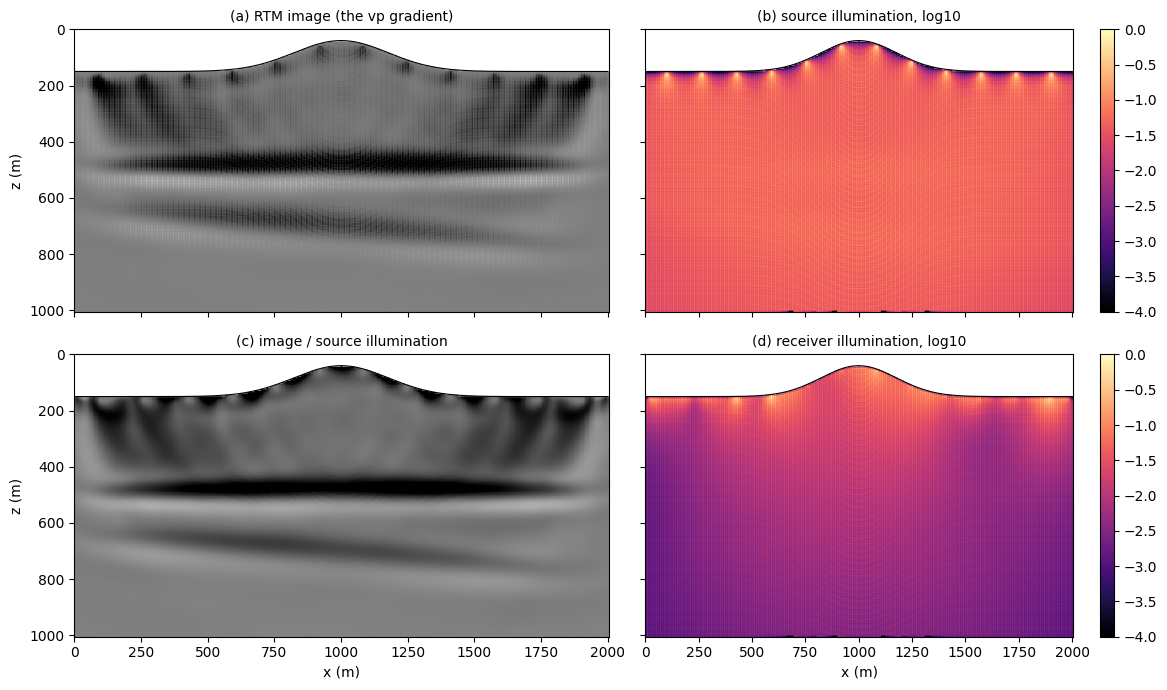

In [5]:
def show(ax, f, title, cmap="gray", q=0.98, log=False):
    f = np.where(Z < top[None, :], np.nan, f)
    if log:
        f = np.log10(f / np.nanmax(f) + 1e-6)
        kw = dict(vmin=-4, vmax=0)
    else:
        m = np.nanquantile(np.abs(np.where(air, np.nan, f)), q)
        kw = dict(vmin=-m, vmax=m)
    im = ax.imshow(f, cmap=cmap, aspect="auto", extent=[0, NX * DH, NZ * DH, 0], **kw)
    ax.plot(xg, top, "k", lw=0.8); ax.set_title(title, fontsize=10)
    return im


fig, ax = plt.subplots(2, 2, figsize=(12, 7), sharex=True, sharey=True)
show(ax[0, 0], image, "(a) RTM image (the vp gradient)")
plt.colorbar(show(ax[0, 1], S, "(b) source illumination, log10", cmap="magma", log=True), ax=ax[0, 1])
show(ax[1, 0], compensated, "(c) image / source illumination")
plt.colorbar(show(ax[1, 1], R, "(d) receiver illumination, log10", cmap="magma", log=True), ax=ax[1, 1])
for a in ax[1]: a.set_xlabel("x (m)")
for a in ax[:, 0]: a.set_ylabel("z (m)")
plt.tight_layout(); plt.show()

The raw image (a) fades with depth and under the hill's flanks, where less energy arrives; the
source illumination (b) has the same pattern, and the ratio (c) brings the two reflectors to a
comparable level along their length. The fine lines in (a) and (b), a few per element, are the
mesh's quadrature weights, which the ratio divides out. The receiver illumination (d) follows
the receivers along the surface and fades at depth.

## 4. Notes

- **Where it runs.** On `impl='eager'`, and on `impl='c'` for the 2-D C-PML paths (potential,
  elastic, fluid-solid), with shot batches and boundary saving. Turning it on does not change
  the gradient.
- **Preconditioning.** For FWI, `grad / (S + eps)` is the pseudo-Hessian preconditioner; `S`
  and `R` together give the symmetric `sqrt(S R)`.
- **Which records.** Record the field itself, as here, when you need `R`: a derived receiver
  such as `p = -chi_tt` weights the adjoint source by `omega^4`.

---

<p><strong>Download this notebook</strong> &mdash; <a href="48_sem_illumination.ipynb" download><code>48_sem_illumination.ipynb</code></a> &middot; or <a href="https://github.com/DeepWave-KAUST/sweep/blob/dev/docs/notebooks/48_sem_illumination.ipynb">view on GitHub</a></p>